# Week 9 — Data Visualization
**Phase 2: Python for Data Analysis**

On Dune you write a query, click "Add visualization", and pick a chart type. This week you learn what happens behind that button: how to turn a DataFrame into a chart you fully control, from a quick exploratory plot to an interactive piece you can publish.

**What you'll build:** ETH price charts, DEX volume bars, a TVL area chart, a gas-fee heatmap, candlesticks, and a final desk dashboard.

**Three libraries, three jobs:**

| Library | Best for | Style |
|---|---|---|
| **Matplotlib** | Total control, static charts, the foundation of everything | Explicit, verbose |
| **Seaborn** | Statistical charts (distributions, heatmaps) in one line | Built on Matplotlib, takes DataFrames |
| **Plotly** | Interactive charts (hover, zoom), shareable HTML | Declarative, web-native |

**Prerequisites:** Week 8 (Pandas & NumPy). Every chart this week starts with a `groupby`, `pivot` or `resample` you already know.

## 0. Setup

In [1]:
# pip install matplotlib seaborn plotly if you haven't installed it yet
import os
import sys
sys.path.insert(0, "../../phase-1-python-fundamentals/week-05-functions-modules")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from blockchain_utils import *          # fmt_usd, fmt_large, shorten_address, ...
from viz_data import *                  # datasets + PROTOCOL_COLORS

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100 #this is used to make the charts of high resolution and look better when you save them as PNGs
plt.rcParams["axes.spines.top"] = False #removes the top and right spines from the plots making it look cleaner and more modern
plt.rcParams["axes.spines.right"] = False

ohlc   = make_eth_ohlc()        # daily ETH candles + volume
trades = make_dex_trades()      # DEX trades (Week 8)
gas    = make_gas_prices()      # hourly base fee (Week 8)
tvl    = make_tvl()             # daily TVL, long format (Week 8)
alloc  = make_allocation()      # a small portfolio

os.makedirs("charts", exist_ok=True)   #this creates a folder called charts if it doesn't exist yet
print("ready:", ohlc.shape, trades.shape, gas.shape, tvl.shape)

ready: (120, 6) (1000, 9) (336, 2) (360, 3)


## 1. Choosing the chart before writing the code

The most common visualization mistake isn't a coding mistake, it's picking the wrong chart. Start from the **question**:

| Your question | Chart | Example |
|---|---|---|
| How does X change over time? | **Line** | ETH price, daily active wallets |
| How do categories compare? | **Bar** (sorted) | Volume by protocol |
| How do parts add up over time? | **Stacked area** | TVL by protocol |
| What is the shape of the data? | **Histogram** / box plot | Trade-size distribution |
| Are two numbers related? | **Scatter** | Trade size vs gas cost |
| Where are the patterns across two categories? | **Heatmap** | Gas by weekday x hour |
| What did price do within each period? | **Candlestick** | ETH daily OHLC |
| What share is each part? | **Bar** (pie only for 2-4 parts) | Portfolio allocation |

### 1.1 Dune visualization types, mapped to Python

| Dune | Matplotlib | Plotly |
|---|---|---|
| Line chart | `ax.plot()` | `px.line()` |
| Bar chart | `ax.bar()` / `ax.barh()` | `px.bar()` |
| Area chart | `ax.stackplot()` | `px.area()` |
| Scatter plot | `ax.scatter()` | `px.scatter()` |
| Pie chart | `ax.pie()` | `px.pie()` |
| Counter | `print(fmt_large(x))` | `go.Indicator` |
| Table | `df` / `df.style` | `go.Table` |

**The key parallel:** a Dune chart plots your query result directly, so your SQL does the aggregation (`GROUP BY`, `date_trunc`). It's identical here: **aggregate with Pandas first, then plot the small result.** Never plot a million raw rows if the question is about daily totals.

## 2. Matplotlib: the anatomy of a chart

### 2.1 Figure and Axes

Two objects matter:

- **Figure**: the whole canvas (the window or the image file)
- **Axes**: one chart on that canvas (the box with x/y axes, lines, labels)

A Figure can hold one Axes or a grid of them. `plt.subplots()` creates both and returns them. This is the **object-oriented** style and the one to use. (The older `plt.plot(...)` style hides the objects behind global state, which works for quick tests but turns confusing the moment you have two charts.)

```python
fig, ax = plt.subplots(figsize=(width_inches, height_inches))
ax.plot(x, y)             # draw ON this specific Axes
ax.set_title("...")
```

Here's the first chart with nothing but defaults:

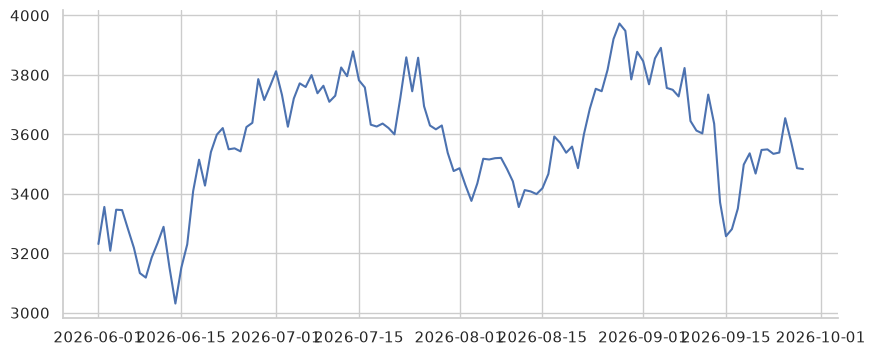

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ohlc["date"], ohlc["close"])

It's a chart, but nobody could use it. No title, no units, the y-axis is bare numbers, and the date labels will collide as soon as the window narrows. A chart needs to be readable **without you explaining it.**

### 2.2 Making it readable: labels, formatters, annotation

Two formatting tools you'll use constantly:

- `mdates.DateFormatter` / locators control date ticks
- `FuncFormatter` turns any function into a tick formatter (here: `3500` -> `$3,500`)

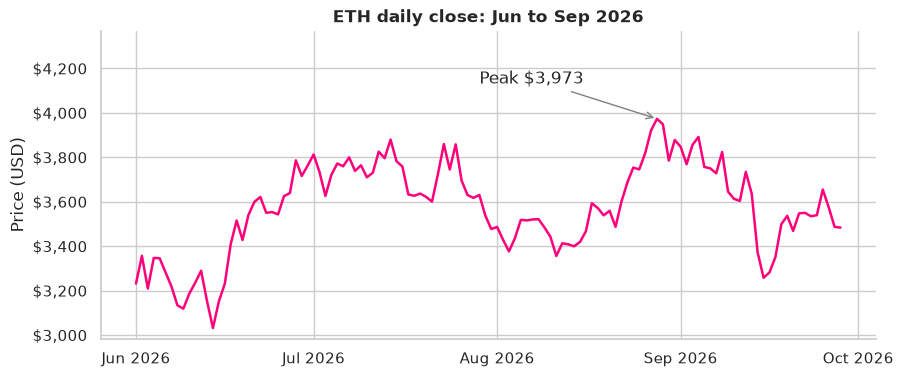

In [2]:
usd = FuncFormatter(lambda v, _: f"${v:,.0f}")        # tick formatter: 3500 -> $3,500

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ohlc["date"], ohlc["close"], color=PROTOCOL_COLORS["Uniswap"], linewidth=1.8)

ax.set_title("ETH daily close: Jun to Sep 2026", loc="center", fontweight="bold")
ax.set_ylabel("Price (USD)")
ax.yaxis.set_major_formatter(usd)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Annotate the peak: the one number the reader should remember
peak = ohlc.loc[ohlc["close"].idxmax()]
ax.annotate(f"Peak {fmt_usd(peak['close'], 0)}",
            xy=(peak["date"], peak["close"]),
            xytext=(peak["date"] - pd.Timedelta(days=30), peak["close"] * 1.04),
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_ylim(top=peak["close"] * 1.10)
fig.savefig("charts/lesson_eth_price.png", dpi=150, bbox_inches="tight")

Same data, now it communicates. Notice how little changed: a title, one formatter, one annotation.

### 2.3 Overlaying series: moving averages

From Week 8: `rolling(n).mean()` is `AVG() OVER (ROWS n-1 PRECEDING)`. Plotting several series on one Axes is just several `ax.plot` calls. Give each a `label`, then call `ax.legend()` once.

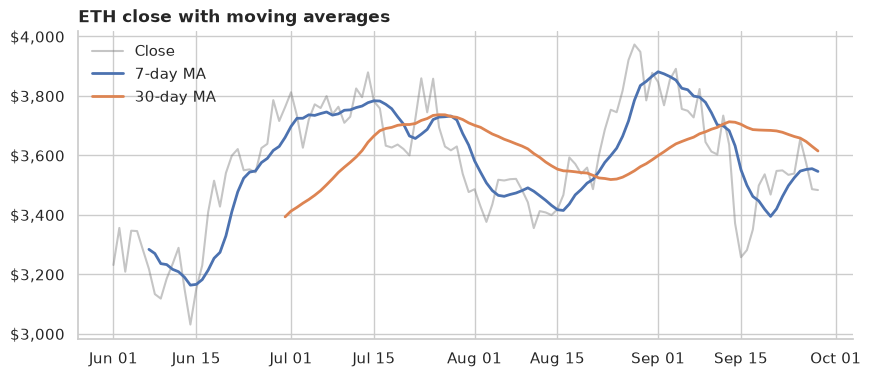

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ohlc["date"], ohlc["close"], label="Close", alpha=0.45, color="gray")
ax.plot(ohlc["date"], ohlc["close"].rolling(7).mean(),  label="7-day MA",  linewidth=2)
ax.plot(ohlc["date"], ohlc["close"].rolling(30).mean(), label="30-day MA", linewidth=2)

ax.set_title("ETH close with moving averages", loc="left", fontweight="bold")
ax.yaxis.set_major_formatter(usd)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(frameon=False)

The MA lines start later than the price line because the first 6 (or 29) values are `NaN`: not enough history to fill the window. Matplotlib simply skips `NaN`, which is the behaviour you want.

## 3. Bar charts

Bars compare **categories**. Three rules:

1. **Sort them** (largest first, unless the categories have a natural order like months). An unsorted bar chart makes the reader do the sorting.
2. **Start at zero.** Bar *length* encodes the value, so a truncated axis lies.
3. **Use horizontal bars (`barh`) when labels are long** (wallet addresses, token names).

### 3.1 Vertical bars with value labels

In [3]:
vol = trades.groupby("protocol")["amount_usd"].sum().sort_values(ascending=False) 
print(vol)

protocol
Uniswap      1561473.47
Curve         563482.96
Sushiswap     535068.05
Balancer      320958.61
Name: amount_usd, dtype: float64


(0.0, 1748850.2864)

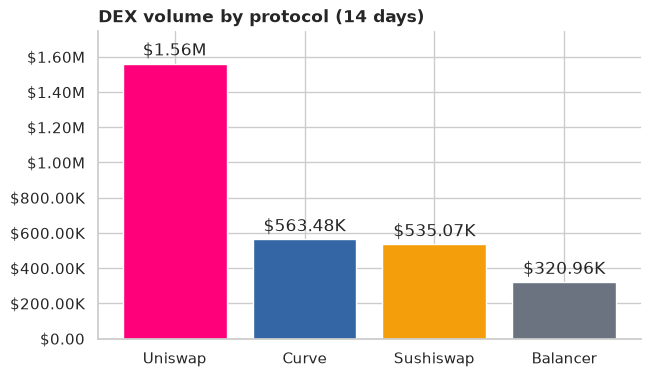

In [5]:
vol = trades.groupby("protocol")["amount_usd"].sum().sort_values(ascending=False)   # GROUP BY ... ORDER BY DESC

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(vol.index, vol.values, color=[PROTOCOL_COLORS[p] for p in vol.index])
ax.bar_label(bars, labels=[fmt_large(v) for v in vol.values], padding=3)      # label on top of each bar
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_large(v)))
ax.set_title("DEX volume by protocol (14 days)", loc="left", fontweight="bold")
ax.set_ylim(top=vol.max() * 1.12)       # headroom for the labels

### 3.2 Horizontal bars for long labels

A wallet leaderboard is the classic case. We pass `shorten_address` (your Week 5 function) to keep the labels short. `barh` draws the **first** item at the **bottom**, so sort ascending to get the biggest at the top.

Text(0.0, 1.0, 'Top 15 wallets by volume')

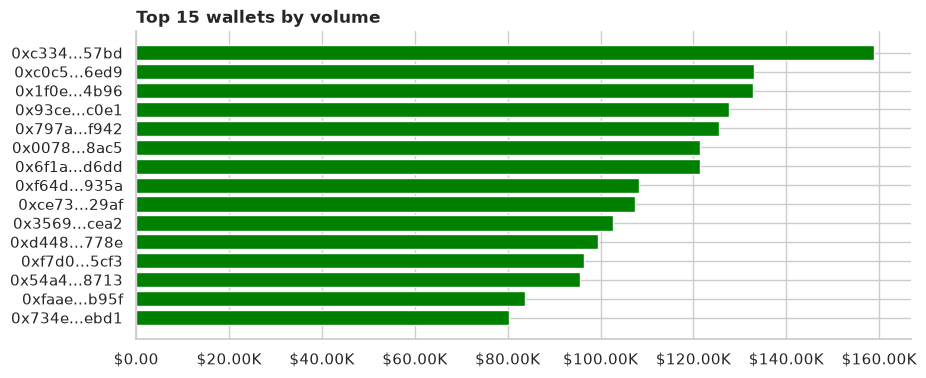

In [4]:
top = trades.groupby("wallet")["amount_usd"].sum().nlargest(15).sort_values()      # ascending for barh

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([shorten_address(w) for w in top.index], top.values, color="green")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_large(v)))
ax.set_title("Top 15 wallets by volume", loc="left", fontweight="bold")

### 3.3 Grouped and stacked bars (from a pivot)

Pandas can plot a DataFrame directly: each **column** becomes a series, each **row** a group. So the work is shaping the pivot, and Week 8's `pivot_table` is exactly that.

- **Grouped** (side by side): best for comparing the series *within* each category
- **Stacked**: best for showing the total and the composition, but only the bottom series is easy to compare

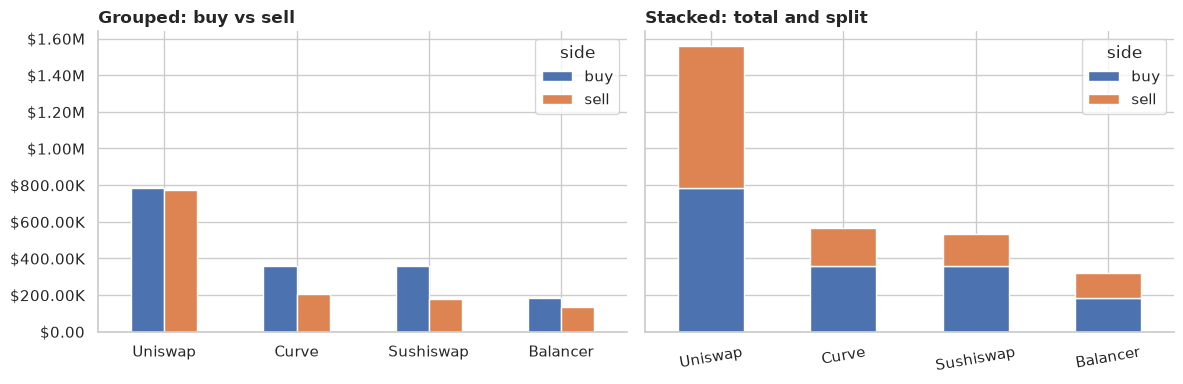

In [7]:
pv = trades.pivot_table(index="protocol", columns="side", values="amount_usd", aggfunc="sum")
pv = pv.loc[vol.index]                      # same protocol order as before

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
pv.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Grouped: buy vs sell", loc="left", fontweight="bold")
pv.plot(kind="bar", stacked=True, ax=axes[1], rot=10)
axes[1].set_title("Stacked: total and split", loc="left", fontweight="bold")
for ax in axes:
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_large(v)))
    ax.set_xlabel("")
fig.tight_layout()

## 4. Scatter plots and log scales

A scatter plot asks "are these two numbers related?" Let's test whether bigger trades pay more gas. First compute the gas cost in USD (Week 8), dropping rows with no gas price.

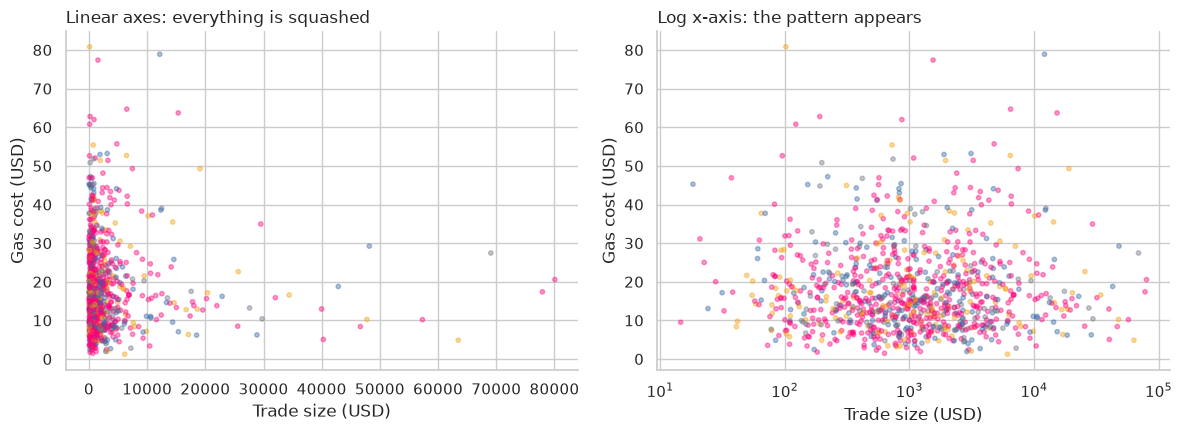

In [5]:
d = (trades.dropna(subset=["gas_price_gwei"])
           .assign(gas_cost_usd=lambda x: x["gas_used"] * x["gas_price_gwei"] / 1e9 * 3_250))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(d["amount_usd"], d["gas_cost_usd"], s=10, alpha=0.4, c=d['protocol'].map(PROTOCOL_COLORS))
#s=10 is the size of the points while alpha=0.4 is the transparency of the points, making them slightly see-through.
#c=d['protocol'].map(PROTOCOL_COLORS) is used to color the points based on the protocol, using the PROTOCOL_COLORS dictionary to map each protocol to a specific color. 
# This allows for visual differentiation of the data points based on the protocol they belong to.
axes[0].set_title("Linear axes: everything is squashed", loc="left")

axes[1].scatter(d["amount_usd"], d["gas_cost_usd"], s=10, alpha=0.4, c=d['protocol'].map(PROTOCOL_COLORS))
axes[1].set_xscale("log")
axes[1].set_title("Log x-axis: the pattern appears", loc="left")

for ax in axes:
    ax.set_xlabel("Trade size (USD)")
    ax.set_ylabel("Gas cost (USD)")
fig.tight_layout()

Trade sizes span 4 orders of magnitude (a handful of whales, a mass of small trades), so on a linear axis nearly every point is crushed against the left edge. A **log scale** gives each power of ten equal space.

Reading the right panel: the cloud is **flat**. Gas cost doesn't grow with trade size, which is what you'd expect: gas pays for computation and network congestion, not for how much money moves. A $50 swap and a $50,000 swap cost about the same to execute.

Two more scatter tools: `alpha` (transparency) so overlapping points build up density instead of hiding each other, and one `scatter` call per category to color by group:

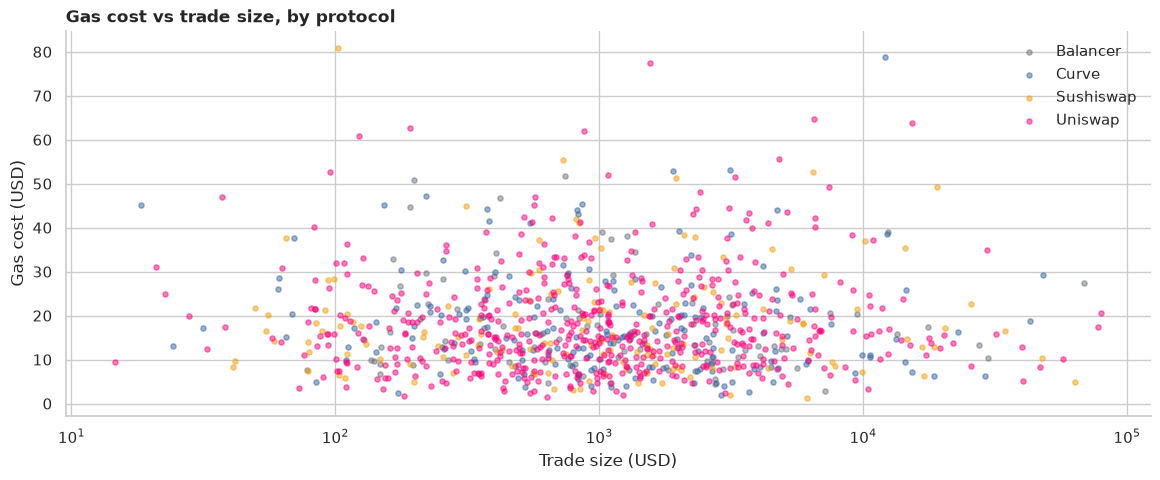

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
for proto, g in d.groupby("protocol"):
    ax.scatter(g["amount_usd"], g["gas_cost_usd"], s=14, alpha=0.5,
               color=PROTOCOL_COLORS[proto], label=proto)
ax.set_xscale("log")
ax.set_xlabel("Trade size (USD)")
ax.set_ylabel("Gas cost (USD)")
ax.set_title("Gas cost vs trade size, by protocol", loc="left", fontweight="bold")
ax.legend(frameon=False)

## 5. Area charts: composition over time

A **stacked area** chart shows how a total is made of parts over time. It's the standard chart for TVL by protocol. `stackplot` wants one x array and one y array per layer. After Week 8 you know the shape: **pivot long to wide**, one column per protocol.

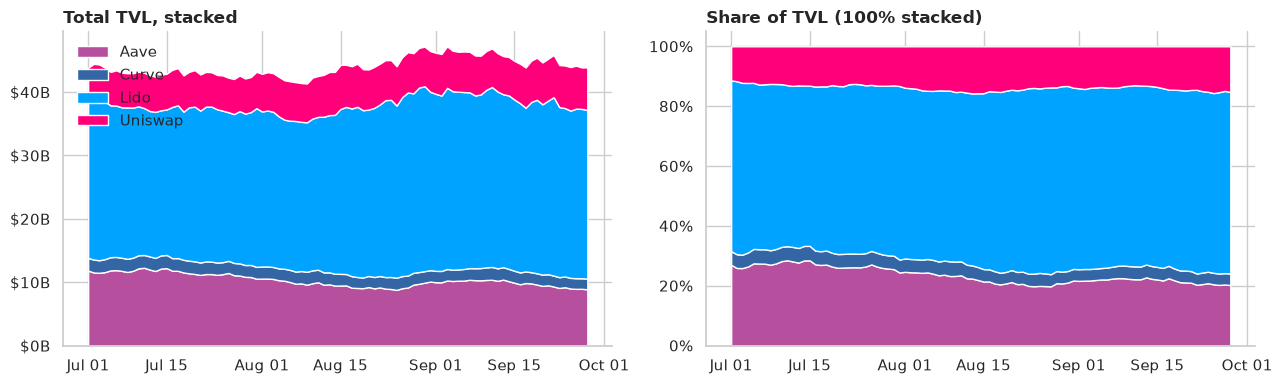

In [6]:
wide = tvl.pivot(index="date", columns="protocol", values="tvl_usd")      # long -> wide
billions = FuncFormatter(lambda v, _: f"${v/1e9:.0f}B")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: absolute values (answers: how big is the total, and what is it made of?)
axes[0].stackplot(wide.index, wide.T.values, labels=wide.columns,
                  colors=[PROTOCOL_COLORS[c] for c in wide.columns])
axes[0].yaxis.set_major_formatter(billions)
axes[0].set_title("Total TVL, stacked", loc="left", fontweight="bold")
axes[0].legend(loc="upper left", frameon=False)

# Right: 100% stacked (answers: who is gaining or losing SHARE?)
share = wide.div(wide.sum(axis=1), axis=0) * 100
axes[1].stackplot(share.index, share.T.values,
                  colors=[PROTOCOL_COLORS[c] for c in share.columns])
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
axes[1].set_title("Share of TVL (100% stacked)", loc="left", fontweight="bold")

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()

Two different questions, two different charts from the same data. The left panel shows the total moving; the right panel strips out the total to show **market share** shifting. (In SQL the right panel is `tvl / SUM(tvl) OVER (PARTITION BY date)`; in Pandas it's the `.div(sum, axis=0)` line.)

**Caution:** in a stacked area only the bottom layer has a true baseline. The upper layers' shapes are distorted by everything beneath them, so don't read exact values off them. If precise comparison matters, use lines.

## 6. Pie charts: use sparingly

Humans judge angles and areas poorly, so a bar chart is almost always clearer than a pie. A pie is defensible only when there are **2 to 4 slices** and the message is "part of a whole". Compare the same portfolio both ways:

In [7]:
# getting the portfolio allocation data we build earlier

print(alloc)

  asset  value_usd
0   ETH      48000
1  WBTC      22000
2  USDC      15000
3   UNI       6500
4  LINK       4200
5  AAVE       2800


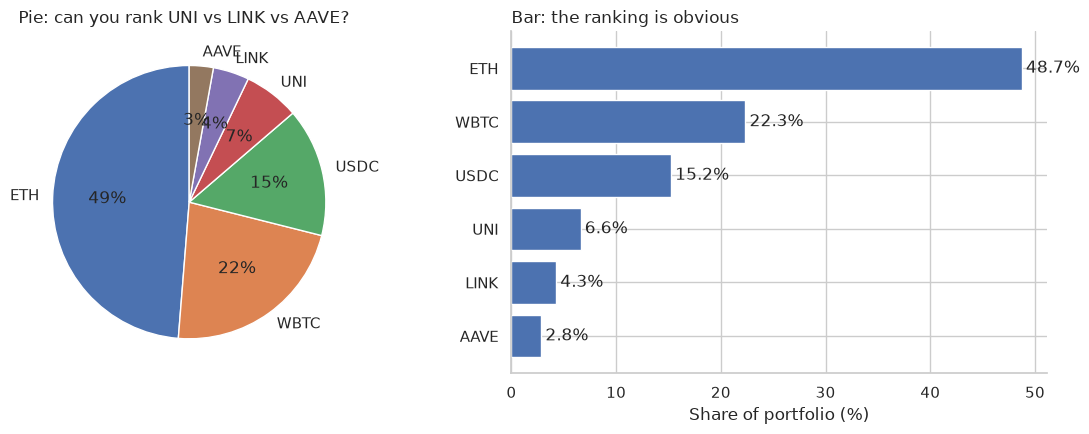

In [8]:
alloc_sorted = alloc.sort_values("value_usd", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].pie(alloc_sorted["value_usd"], labels=alloc_sorted["asset"], autopct="%1.0f%%", startangle=90)
axes[0].set_title("Pie: can you rank UNI vs LINK vs AAVE?", loc="left")

pct = alloc_sorted["value_usd"] / alloc_sorted["value_usd"].sum() * 100
bars = axes[1].barh(alloc_sorted["asset"][::-1], pct[::-1])
axes[1].bar_label(bars, labels=[f"{p:.1f}%" for p in pct[::-1]], padding=3)
axes[1].set_title("Bar: the ranking is obvious", loc="left")
axes[1].set_xlabel("Share of portfolio (%)")
fig.tight_layout()

## 7. Subplots and shared axes

`plt.subplots(rows, cols)` returns an array of Axes. Two habits make multi-panel charts good:

- `sharex=True` so panels line up and zooming one zooms all
- `height_ratios` so the main panel is taller than the supporting one

The classic finance layout is **price on top, volume below**. We'll color volume bars by whether the day closed up or down, which is a second layer of information at no extra space.

In [18]:
print(ohlc.head())

        date     open     high      low    close    volume_usd
0 2026-06-01  3200.00  3232.98  3164.82  3231.26  6.511039e+09
1 2026-06-02  3231.26  3377.75  3196.39  3355.88  6.277388e+09
2 2026-06-03  3355.88  3379.49  3203.34  3208.70  6.892624e+09
3 2026-06-04  3208.70  3356.67  3198.00  3346.56  8.459931e+09
4 2026-06-05  3346.56  3382.38  3338.68  3345.28  5.278228e+09


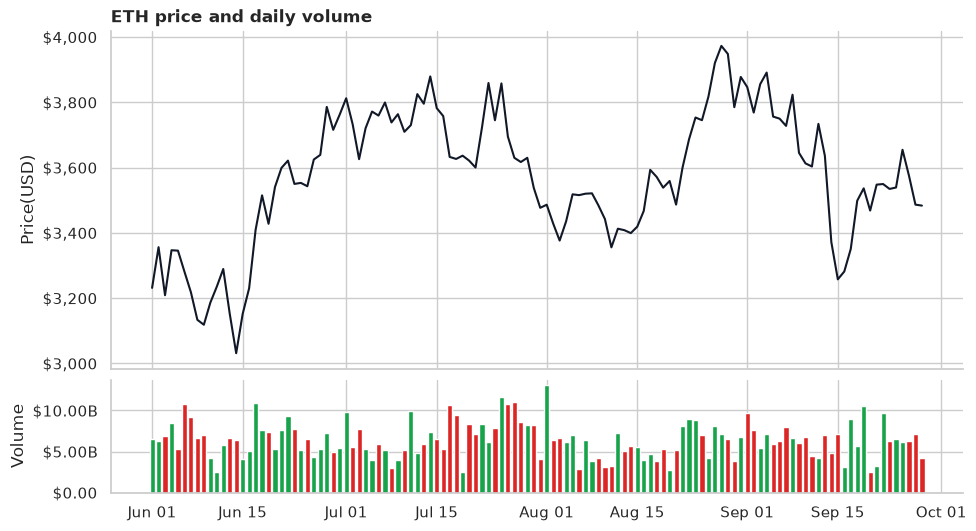

In [40]:
up = ohlc["close"] >= ohlc["open"]
colors = np.where(up, "#16a34a", "#dc2626")             # np.where = CASE WHEN (Week 8)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(11, 6),
                               gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05})
ax1.plot(ohlc["date"], ohlc["close"], color="#111827", linewidth=1.5)
ax1.yaxis.set_major_formatter(usd)
ax1.set_ylabel("Price(USD)")
ax1.set_title("ETH price and daily volume", loc="left", fontweight="bold")

ax2.bar(ohlc["date"], ohlc["volume_usd"], color=colors, width=0.8)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_large(v)))
ax2.set_ylabel("Volume")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

## 8. Candlesticks

A candle encodes four prices for a period:

```
        |  <- high  (wick)
      +---+
      |   |  <- body spans open to close
      +---+     green if close >= open, red otherwise
        |  <- low   (wick)
```

Matplotlib has no candlestick primitive, but it's two simple layers: a thin vertical line (`vlines`) from low to high, and a bar from open to close drawn on top. Building it once shows you exactly what the chart means. (Plotly, section 10, has it built in.)

Text(0.0, 1.0, 'ETH daily candles (last 45 days)')

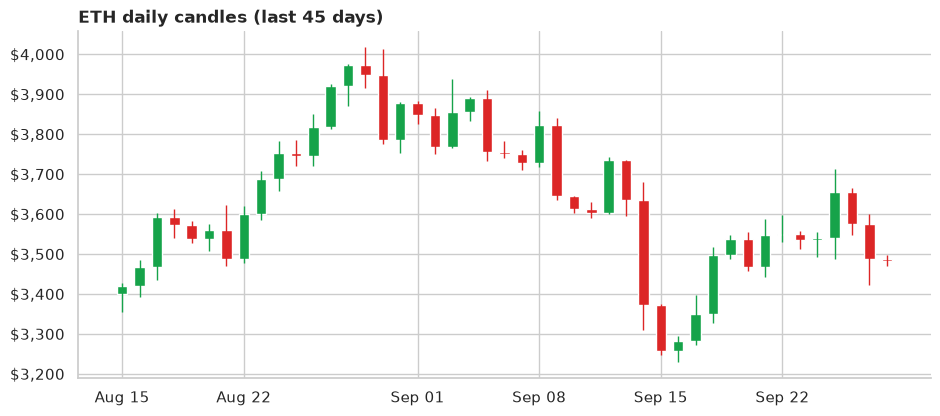

In [39]:
sub = ohlc.tail(45)
is_up = (sub["close"] >= sub["open"]).to_numpy()
col = np.where(is_up, "#16a34a", "#dc2626")

fig, ax = plt.subplots(figsize=(11, 4.5))
#this line of code is used to create vertical lines (wicks) for each candlestick in a candlestick chart. 
# The x-coordinates of the lines are determined by the "date" column in the "sub" DataFrame, while the y-coordinates are determined by the "low" and "high" columns.
ax.vlines(sub["date"], sub["low"], sub["high"], colors=col, linewidth=1)     # wicks
#this line of code is used to create a bar chart that represents the bodies of the candlesticks in a candlestick chart. 
# The height of each bar is determined by the absolute difference between the closing and opening prices for each day
ax.bar(sub["date"], (sub["close"] - sub["open"]).abs(),
       bottom=sub[["open", "close"]].min(axis=1), color=col, width=0.6)  # bodies (the bottom is decided by the min of open and close)
ax.yaxis.set_major_formatter(usd)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title("ETH daily candles (last 45 days)", loc="left", fontweight="bold")

## 9. Seaborn: statistical charts in one line

Seaborn is built **on top of** Matplotlib. It takes a DataFrame and column names (`data=df, x="col"`) and does the aggregation and styling for you. It returns a Matplotlib `Axes`, so everything from sections 2-8 (titles, formatters, `savefig`) still works on it. Use it for distributions and heatmaps.

### 9.1 Histograms: the shape of the data

A histogram answers "what does a typical value look like, and how spread out are they?" This is where Week 8's warning about the mean lying on heavy-tailed data becomes visible.

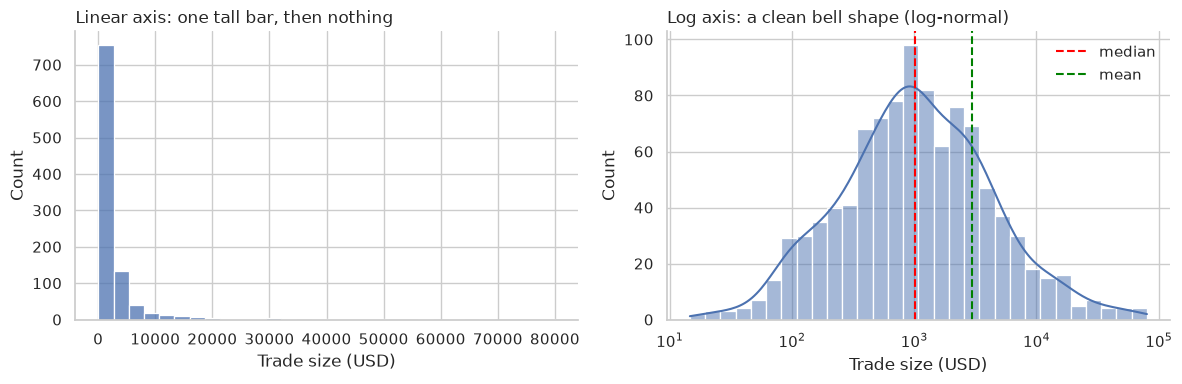

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(trades["amount_usd"], bins=30, ax=axes[0])
axes[0].set_title("Linear axis: one tall bar, then nothing", loc="left")

sns.histplot(trades["amount_usd"], bins=30, log_scale=True, kde=True, ax=axes[1]) 
#the bins tell how many bars to use in the histogram, 
# log_scale=True applies a logarithmic scale to the x-axis, and kde=True adds a kernel density estimate curve to the histogram.
axes[1].set_title("Log axis: a clean bell shape (log-normal)", loc="left")
axes[1].axvline(trades["amount_usd"].median(), color="red", linestyle="--", label="median")
axes[1].axvline(trades["amount_usd"].mean(), color="green", linestyle="--", label="mean")
axes[1].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("Trade size (USD)")
fig.tight_layout()

On the log axis the data looks like a bell curve: trade sizes are **log-normal**, which is typical of money amounts. Notice the **mean sits well to the right of the median**, pulled by the whales. That gap is the chart's whole message: report the median for "a typical trade".

### 9.2 Box plots: comparing distributions across categories

A box shows the median (line), the middle 50% of values (box), and outliers (dots). It compares *spread* across groups, which a bar of averages cannot.

Text(0.5, 0, '')

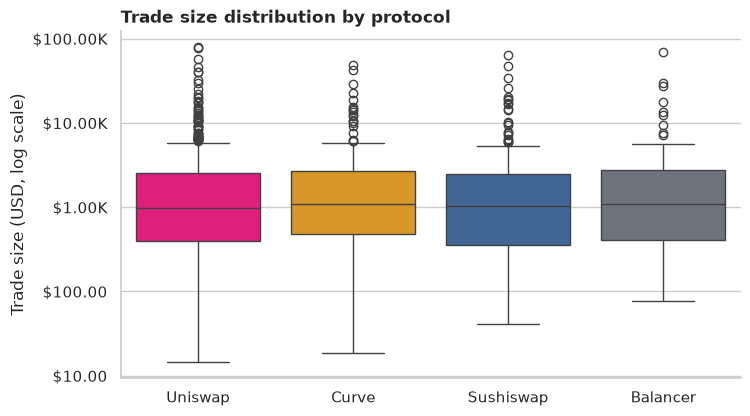

In [34]:
order = vol.index.tolist()          # same protocol order as the bar chart

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=trades, x="protocol", y="amount_usd", order=order, ax=ax,
            palette=[PROTOCOL_COLORS[p] for p in order], hue="protocol", legend=False)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_large(v)))
ax.set_title("Trade size distribution by protocol", loc="left", fontweight="bold")
ax.set_ylabel("Trade size (USD, log scale)")
ax.set_xlabel("")

Seaborn can also aggregate for you: `sns.barplot(..., estimator="median")` is a `GROUP BY` and a chart in one call. Useful for exploring; for published charts prefer to aggregate yourself so you control exactly what's plotted.

Text(0.5, 0, '')

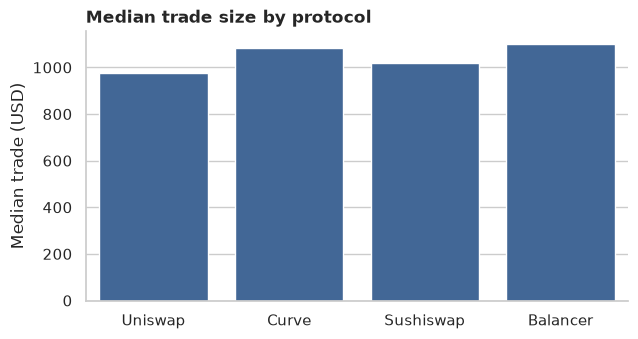

In [35]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(data=trades, x="protocol", y="amount_usd", estimator="median", errorbar=None,
            order=order, ax=ax, color=PROTOCOL_COLORS["Curve"])
ax.set_title("Median trade size by protocol", loc="left", fontweight="bold")
ax.set_ylabel("Median trade (USD)")
ax.set_xlabel("")

### 9.3 Heatmaps: patterns across two categories

A heatmap is a pivot table drawn with color. It's the right chart for "when is gas expensive?": rows = weekday, columns = hour, color = mean base fee. The Pandas work is `dt.dayofweek`, `dt.hour`, `pivot_table`, all from Week 8.

Text(115.9722222222222, 0.5, '')

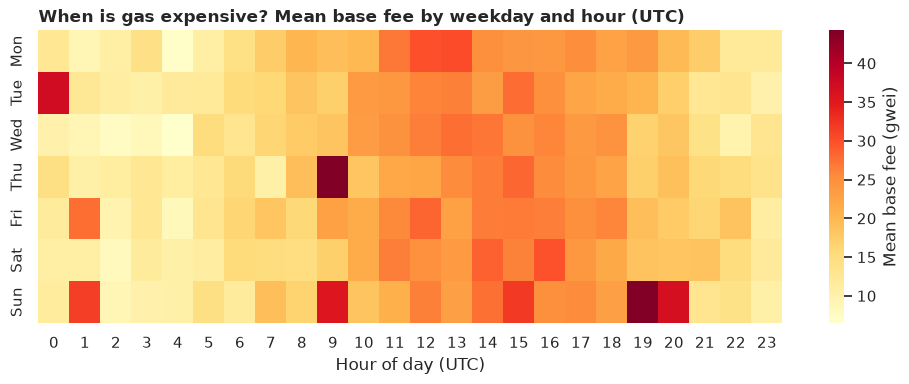

In [10]:
g = gas.assign(weekday=gas["timestamp"].dt.day_name().str[:3],
               hour=gas["timestamp"].dt.hour)
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
pv_gas = g.pivot_table(index="weekday", columns="hour", values="base_fee_gwei", aggfunc="mean").reindex(day_order)

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(pv_gas, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Mean base fee (gwei)"})
ax.set_title("When is gas expensive? Mean base fee by weekday and hour (UTC)", loc="left", fontweight="bold")
ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("")

Always sanity-check how many observations are behind each cell. Our dataset has 14 days, so each weekday/hour cell averages only **2 values**, and a single gas spike can light up a cell (the dark squares). On real data, use months of history before drawing conclusions from a heatmap.

### 9.4 Correlation heatmap

Do protocols' TVL move together? Correlate **daily changes** (not levels, since two trending series always look correlated). `pct_change` is Week 8; `.corr()` returns a matrix; the heatmap makes it readable.

In [11]:
corr = wide.pct_change().dropna().corr()
print(corr)

protocol      Aave     Curve      Lido   Uniswap
protocol                                        
Aave      1.000000  0.082859 -0.101726 -0.061219
Curve     0.082859  1.000000 -0.083939 -0.180001
Lido     -0.101726 -0.083939  1.000000  0.170019
Uniswap  -0.061219 -0.180001  0.170019  1.000000


Text(34.722222222222214, 0.5, '')

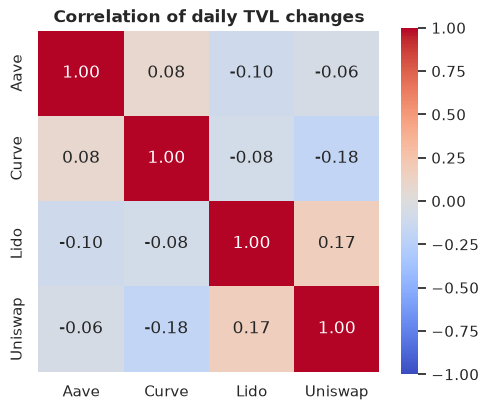

In [12]:
corr = wide.pct_change().dropna().corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title("Correlation of daily TVL changes", loc="center", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")

Values near 0 mean the protocols move independently (expected here, since this data is simulated independently). On real DeFi data you'd typically see strongly positive correlations because everything follows ETH price. That contrast is itself a finding.

## 10. Plotly: interactive charts

Matplotlib produces **images**. Plotly produces **web pages**: hover for exact values, click legend items to hide series, drag to zoom. For on-chain data where you constantly want to ask "what was the exact value on that spike?", this is a big upgrade, and a Plotly chart saves to one HTML file anyone can open (it's the basis of the Phase 2 capstone dashboard).

Two APIs:

- **Plotly Express (`px`)**: one function per chart type, takes a DataFrame. Use this first.
- **Graph Objects (`go`)**: full control and chart types `px` lacks (candlestick). Use when you need it.

### 10.1 Plotly Express: line, with hover

In [ ]:
#print out the data we want to use first to understand the structure
tvl.head()

,date,protocol,tvl_usd
0,2026-07-01,Aave,1.181954e+10
1,2026-07-02,Aave,1.151829e+10
2,2026-07-03,Aave,1.147259e+10
3,2026-07-04,Aave,1.158054e+10
4,2026-07-05,Aave,1.185524e+10


In [19]:
fig = px.line(tvl, x="date", y="tvl_usd", color="protocol",
              color_discrete_map=PROTOCOL_COLORS,
              title="TVL by protocol", labels={"tvl_usd": "TVL (USD)", "date": ""})
fig.update_layout(hovermode="x unified", legend_title_text="")
fig.update_yaxes(tickprefix="$", tickformat=".2s")
fig.show()

`color="protocol"` is the `GROUP BY` for the chart: Plotly splits the long-format table into one line per protocol. That's why **long format** (one row per date per protocol) is the natural input for Plotly Express, whereas Matplotlib's `stackplot` wanted wide.

Hover over the chart: with `hovermode="x unified"`, one tooltip shows every protocol's value for that date.

### 10.2 Scatter with rich hover data

This is where interactivity pays off: hover any dot to see which transaction it is.

In [20]:
d.head()

,tx_hash,block_time,protocol,pair,wallet,side,amount_usd,gas_used,gas_price_gwei,gas_cost_usd
0,0xb8e2ed8b84c3,2026-09-01 01:28:17,Uniswap,DAI-USDC,0x21ddae9163b29d2eb085b3777ef1c227f89b77b2,sell,1371.42,272713,44.04,39.033412
1,0x58d670101ddd,2026-09-01 01:38:35,Sushiswap,WETH-USDC,0x0078359cc1644d67f7cff560b60221193f998ac5,buy,1031.35,273214,23.94,21.257415
2,0x0149572b51be,2026-09-01 01:46:59,Curve,WETH-USDT,0xc334cfc4bb625d81e850982d8134bcd9e59a57bd,buy,257.58,227318,16.83,12.433726
3,0x06dbd65b239a,2026-09-01 01:49:27,Curve,WETH-USDT,0xc334cfc4bb625d81e850982d8134bcd9e59a57bd,buy,3197.49,133276,28.17,12.201751
4,0x1858f1f7c64c,2026-09-01 01:50:20,Uniswap,DAI-USDC,0xf0da7cf81b3333e512654fd9f5241f373f28f8ee,buy,1092.18,273904,10.84,9.649638


In [31]:
fig = px.scatter(d, x="amount_usd", y="gas_cost_usd", color="protocol",
                 color_discrete_map=PROTOCOL_COLORS, opacity=0.6, log_x=True, log_y=True,
                 hover_data=["tx_hash", "pair", "gas_price_gwei"],
                 title="Gas cost vs trade size (hover for the tx)")
fig.update_layout(legend_title_text="")
fig.show()

### 10.3 Bars: grouped

`barmode="group"` for side by side, `"stack"` for stacked (the Plotly twin of section 3.3).

In [ ]:
by_side = trades.groupby(["protocol", "side"], as_index=False)["amount_usd"].sum()
fig = px.bar(by_side, x="protocol", y="amount_usd", color="side", barmode="group", 
             #you can use barmode="stack" to stack the bars on top of each other instead of grouping them side by side
             category_orders={"protocol": order}, title="Buy vs sell volume",
             labels={"amount_usd": "Volume (USD)"})
fig.update_yaxes(tickprefix="$", tickformat=".2s")
fig.show()

### 10.4 Candlestick + volume with Graph Objects

`px` has no candlestick, so we use `go`. `make_subplots` builds the price-over-volume layout from section 7 in Plotly style. Drag on the chart to zoom into a week; double-click to reset.

In [41]:
ohlc.head()

,date,open,high,low,close,volume_usd
0,2026-06-01,3200.00,3232.98,3164.82,3231.26,6.511039e+09
1,2026-06-02,3231.26,3377.75,3196.39,3355.88,6.277388e+09
2,2026-06-03,3355.88,3379.49,3203.34,3208.70,6.892624e+09
3,2026-06-04,3208.70,3356.67,3198.00,3346.56,8.459931e+09
4,2026-06-05,3346.56,3382.38,3338.68,3345.28,5.278228e+09


In [53]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.75, 0.25], vertical_spacing=0.03)

fig.add_trace(go.Candlestick(x=ohlc["date"], open=ohlc["open"], high=ohlc["high"],
                             low=ohlc["low"], close=ohlc["close"], name="ETH"), row=1, col=1)
fig.add_trace(go.Bar(x=ohlc["date"], y=ohlc["volume_usd"], marker_color=colors,
                     name="Volume", showlegend=False), row=2, col=1)

fig.update_layout(title="ETH daily candles and volume", height=600,
                  xaxis_rangeslider_visible=False, showlegend=False)
fig.update_yaxes(tickprefix="$", row=1, col=1)
fig.show()
fig.write_html("charts/lesson_eth_candles.html", include_plotlyjs="cdn") #this is used to export plotly charts as html

### 10.5 Saving: one HTML file, no server

```python
fig.write_html("charts/eth_candles.html", include_plotlyjs="cdn")
```

`include_plotlyjs="cdn"` keeps the file small (a few hundred KB) by loading the Plotly library from a CDN when someone opens it. The file is fully interactive and can be hosted for free on GitHub Pages, which makes it perfect for a build-in-public portfolio.

### 10.6 Matplotlib vs Plotly: which one?

| | Matplotlib / Seaborn | Plotly |
|---|---|---|
| Output | Static image (PNG, SVG, PDF) | Interactive HTML |
| Best for | Reports, READMEs, papers, tweets | Exploration, dashboards, sharing |
| Control | Pixel-level | High, but web-style |
| Big data | Fine (aggregate first) | Slows past ~100k points in the browser |
| Learning curve | Steeper | Gentler |

**Rule of thumb:** explore and publish interactive work in Plotly; export static images for tweets, READMEs and write-ups with Matplotlib.

In [54]:
fig.write_html("charts/lesson_eth_candles.html", include_plotlyjs="cdn")
print("saved:", sorted(f for f in os.listdir("charts") if f.startswith("lesson_")))

saved: ['lesson_eth_candles.html', 'lesson_eth_price.png']


## 11. The chart-quality checklist

Run through this before you publish any chart. It's the difference between an analyst and someone who can code a plot.

| Check | Why |
|---|---|
| **Title states the finding or the subject**, left-aligned | The reader shouldn't have to guess what they're seeing |
| **Units on every axis** (USD, gwei, %) and **time zone** if relevant | `5` means nothing; `5 gwei` does |
| **Bars start at zero**; lines may not | Bar length encodes value, so truncating lies |
| **Sorted categories** | Let the chart do the ranking |
| **Log scale for heavy-tailed data**, and say so in the label | Otherwise whales flatten everything else |
| **Readable numbers** (`$1.2B`, not `1200000000.0` or `1e9`) | Use `FuncFormatter` |
| **Few colors, used consistently** | Same protocol = same color on every chart (see `PROTOCOL_COLORS`) |
| **Don't encode meaning in red/green alone** | ~8% of men are red-green colorblind; add labels or position |
| **Avoid dual y-axes** | They let you imply any correlation you like |
| **Label the one or two things that matter** | `annotate` the peak, the exploit, the upgrade |
| **State the data window and source** | "Source: simulated data, 14 days" |

## 12. Saving figures

```python
fig.savefig("charts/name.png", dpi=150, bbox_inches="tight")   # PNG for README / tweets
fig.savefig("charts/name.svg", bbox_inches="tight")            # SVG: sharp at any size
fig.savefig("charts/name.pdf", bbox_inches="tight")            # PDF for reports
```

- `dpi=150` is sharp on screens without huge files; use 300 for print
- `bbox_inches="tight"` stops labels getting clipped at the edges
- Always `savefig` **before** `plt.show()` in a plain script (show clears the figure)
- In scripts and servers there is no screen, so use `matplotlib.use("Agg")` (the exercises do this)
- Many figures in a loop? Call `plt.close(fig)` after saving, or memory grows until Matplotlib warns you

## 13. Mini project: the desk dashboard

One function that takes your DataFrames and returns a single polished figure: price and trend, volume by protocol, a gas heatmap, and portfolio allocation. This is the pattern for every report you'll automate: **data in, finished figure out.**

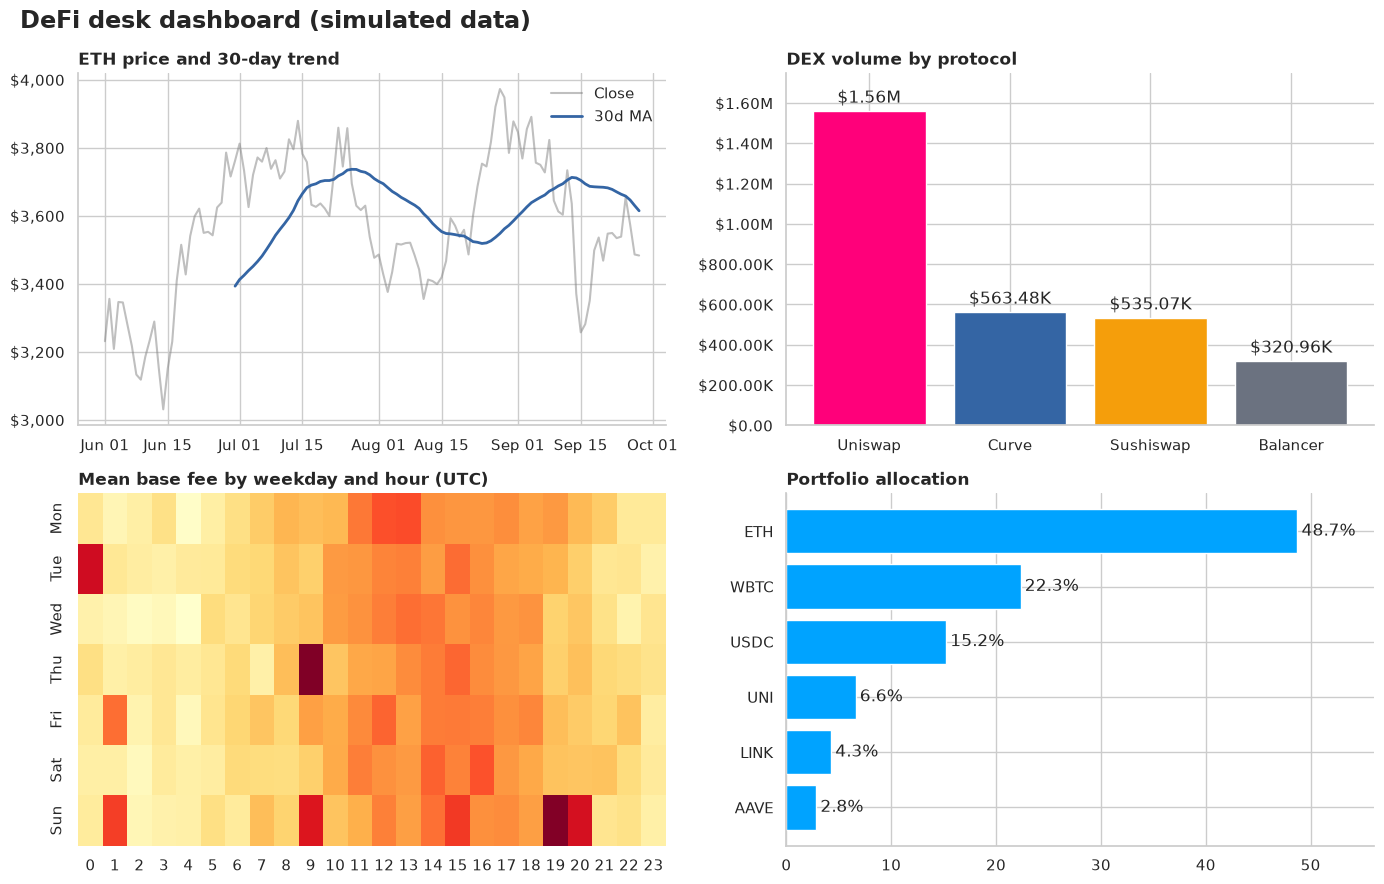

In [55]:
def desk_dashboard(ohlc, trades, gas, alloc):
    """Return a 2x2 Matplotlib dashboard figure from the four core DataFrames."""
    usd0 = FuncFormatter(lambda v, _: f"${v:,.0f}")
    big = FuncFormatter(lambda v, _: fmt_large(v))

    fig, ax = plt.subplots(2, 2, figsize=(14, 9))

    # [0,0] price + 30d trend
    ax[0, 0].plot(ohlc["date"], ohlc["close"], color="gray", alpha=0.5, label="Close")
    ax[0, 0].plot(ohlc["date"], ohlc["close"].rolling(30).mean(), color=PROTOCOL_COLORS["Curve"],
                  linewidth=2, label="30d MA")
    ax[0, 0].yaxis.set_major_formatter(usd0)
    ax[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax[0, 0].set_title("ETH price and 30-day trend", loc="left", fontweight="bold")
    ax[0, 0].legend(frameon=False)

    # [0,1] volume by protocol
    v = trades.groupby("protocol")["amount_usd"].sum().sort_values(ascending=False)
    b = ax[0, 1].bar(v.index, v.values, color=[PROTOCOL_COLORS[p] for p in v.index])
    ax[0, 1].bar_label(b, labels=[fmt_large(x) for x in v.values], padding=3)
    ax[0, 1].yaxis.set_major_formatter(big)
    ax[0, 1].set_ylim(top=v.max() * 1.12)
    ax[0, 1].set_title("DEX volume by protocol", loc="left", fontweight="bold")

    # [1,0] gas heatmap (no colorbar: keeps the 2x2 grid clean)
    gg = gas.assign(weekday=gas["timestamp"].dt.day_name().str[:3], hour=gas["timestamp"].dt.hour)
    pv = (gg.pivot_table(index="weekday", columns="hour", values="base_fee_gwei", aggfunc="mean")
            .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]))
    sns.heatmap(pv, cmap="YlOrRd", cbar=False, ax=ax[1, 0])
    ax[1, 0].set_title("Mean base fee by weekday and hour (UTC)", loc="left", fontweight="bold")
    ax[1, 0].set_xlabel("")
    ax[1, 0].set_ylabel("")

    # [1,1] allocation as bars
    a = alloc.sort_values("value_usd")
    pct = a["value_usd"] / a["value_usd"].sum() * 100
    hb = ax[1, 1].barh(a["asset"], pct, color=PROTOCOL_COLORS["Lido"])
    ax[1, 1].bar_label(hb, labels=[f"{p:.1f}%" for p in pct], padding=3)
    ax[1, 1].set_xlim(right=pct.max() * 1.15)
    ax[1, 1].set_title("Portfolio allocation", loc="left", fontweight="bold")

    fig.suptitle("DeFi desk dashboard (simulated data)", fontsize=17, fontweight="bold", x=0.02, ha="left")
    fig.tight_layout()
    return fig

fig = desk_dashboard(ohlc, trades, gas, alloc)
fig.savefig("charts/lesson_desk_dashboard.png", dpi=150, bbox_inches="tight")

Open `charts/lesson_desk_dashboard.png`. That's a chart you could put at the top of a GitHub README or a thread. Commit your best charts: for a build-in-public portfolio, a visible chart is worth more than a page of description.

## 14. Common pitfalls

| Pitfall | What happens | Fix |
|---|---|---|
| Plotting raw rows when the question is about totals | Slow, unreadable | `groupby` / `resample` first, plot the small result |
| `plt.plot()` mixed with `ax.plot()` | Lines land on the wrong chart | Stick to `fig, ax = plt.subplots()` |
| Dates stored as strings | Axis treats them as categories, labels collide | `parse_dates=` / `pd.to_datetime()` |
| `NaN` in a scatter | Points silently dropped, counts differ | `dropna()` first so you know the true n |
| Truncated y-axis on bars | Differences look dramatic | Start bars at zero |
| Pie with 6+ slices | Unreadable | Sorted bar chart |
| Dual y-axes | Implied correlation | Two stacked panels with `sharex=True` |
| `1e6` / `1e9` on axes | Reader must decode | `FuncFormatter` with `fmt_large` |
| Overlapping tick labels | Illegible dates | `DateFormatter` + `MonthLocator`, or `fig.autofmt_xdate()` |
| Forgetting `tight_layout()` | Labels clipped or overlapping across panels | `fig.tight_layout()` before saving |
| Hundreds of thousands of points in Plotly | Browser lags | Aggregate, or use Matplotlib |

## Lesson summary

| Concept | Dune / SQL idea | Python |
|---|---|---|
| Figure vs Axes | (visualization panel) | `fig, ax = plt.subplots()` |
| Line chart | Line chart | `ax.plot()` / `px.line()` |
| Moving average overlay | `AVG() OVER (ROWS ...)` | `.rolling(n).mean()` then `ax.plot` |
| Bar chart | Bar chart | `ax.bar()` / `ax.barh()` / `px.bar()` |
| Grouped / stacked bars | pivoted result | `pivot_table` then `.plot(kind="bar", stacked=)` |
| Scatter | Scatter plot | `ax.scatter()` / `px.scatter()` |
| Log scale | n/a | `ax.set_xscale("log")` / `log_scale=True` |
| Stacked area | Area chart | `ax.stackplot()` (wide) / `px.area()` (long) |
| 100% share | `x / SUM(x) OVER (PARTITION BY date)` | `wide.div(wide.sum(axis=1), axis=0)` |
| Subplots | Dashboard | `plt.subplots(r, c, sharex=True)` |
| Candlestick | n/a | `vlines` + `bar` / `go.Candlestick` |
| Distribution | `approx_percentile` | `sns.histplot` / `sns.boxplot` |
| Heatmap | pivot table | `sns.heatmap(pivot_table)` |
| Interactive | Dune dashboard | Plotly, saved with `write_html` |
| Tick formatting | n/a | `FuncFormatter(lambda v, _: ...)` |
| Save | Export | `fig.savefig(..., dpi=150, bbox_inches="tight")` |

**Key ideas:** aggregate first, then plot. Pick the chart from the question. Log scales for heavy tails. Format numbers for humans. Same entity, same color, everywhere.

## What's next

**Week 10: APIs & SQL from Python.** So far the data came from generators. Next you pull **real data** from CoinGecko, DefiLlama and Etherscan with `requests` (rate limits, pagination), store it in SQLite, and query it with both SQL and Pandas. The charts you built here become the output layer of the Phase 2 capstone `defi-dashboard`.

## Commit your work

```bash
cd ~/Desktop/python-for-blockchain-analytics
git add phase-2-python-for-data/week-09-visualization/
git commit -m "phase-2/week-09: data visualization — lesson, exercises, solutions"
git push
```

The `charts/` folder is created by the lesson and exercises. Commit the **lesson charts** (`charts/lesson_*`) as portfolio material; the exercise charts (`charts/ex*.png`) are your scratch work.

Next, work through `exercises.py` (`python3 exercises.py --save` to see your charts). Only open `exercises_solutions.py` after you've attempted them.